# B-8802B · resumo: o que muda no modelo de anomalia sem a temperatura

**Em 3 frases**
1. Em 2026 o erro do modelo de produção sobe por causa da **temperatura** (o mancal esfriou), não por defeito.
2. A falha de 2022 aparece na **vibração**: ela salta em 04/07, e **todos** os modelos que têm vibração alertam nesse
   mesmo momento, ~2 dias antes da falha. Antes de 04/07 os sensores não mostram nada, então nenhum modelo consegue
   avisar mais cedo — a antecedência é limitada pelo dado, não pelo modelo.
3. Por isso a diferença entre os modelos está nos **alertas sem falha** (2026): sem temperatura o erro fica estável;
   só vibração alerta mais em janeiro.

Detalhes e todos os testes: `fe_exploracao_b8802b.ipynb`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts")); sys.path.insert(0, str(RAIZ / "src"))
import fe_exploracao_b8802b as fx
from transpetro_modelos.drift import battery
plt.rcParams.update({"font.size": 11})
TEXTO = "#52514e"
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=11.5, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

ctx = fx.contexto()
R = RAIZ / "results/fe_exploracao"

# um modelo representativo por receita
def receita_fx(var, cand):
    F = fx.features(ctx.pre, var); tr = F[(F.index >= fx.TS) & (F.index < fx.TE)]
    esc = fx.Escala().fit(tr.iloc[:-int(len(tr) * 0.15)])
    m = fx.build_model("vae", F.shape[1], dense_layers=[128, 64, 32], latent_dim=16)
    m.load_state_dict(torch.load(R / "cands" / var / f"{cand}.pt", map_location="cpu")); m.eval()
    pont = lambda pre: fx.erros(m, esc(fx.features(pre, var))).mean(axis=1)
    e25 = pont(ctx.pre).loc["2025"]
    return pont, float(e25.mean() + 6.5 * e25.std())

def receita_producao():   # o próprio bundle em produção (refaz o pré-processamento a partir do dado bruto)
    b = fx.BUNDLE
    return b, json.loads((b / "alarm.json").read_text())["threshold"]

MODELOS = {
    "produção (5 sensores, com temperatura)": ("#2a78d6",) + receita_producao(),
    "sem temperatura (vibração + pressões)": ("#1baf7a",) + receita_fx("vib_press", "l128-64-32_lat16_lr0.0001_s0"),
    "só vibração": ("#eda100",) + receita_fx("vib", "l128-64-32_lat16_lr0.001_s0"),
}

def score_e_alerta(nome, raw):
    """Score bruto (5 min), limiar e alerta com a regra de produção (15 de 20 em 100 min + duração de 1 h)."""
    cor, a, thr = MODELOS[nome]
    if isinstance(a, Path):
        torch.manual_seed(0); r = battery.score(a, raw)
        return r["reconstruction_error"], thr, r["is_anomaly"]
    s = a(fx.temporal(raw))
    return s, thr, fx.alertas(s, thr, raw)
print("modelos:", list(MODELOS))

dado 2025-26: 139264 leituras de 5 min com a bomba operando; 2022: 10091


fração do tempo com a bomba operando em cada falha sintética: {'2026-01-25': np.float64(1.0), '2026-03-05': np.float64(0.68), '2026-04-20': np.float64(0.12), '2026-06-10': np.float64(1.0), '2026-07-15': np.float64(1.0)}


modelos: ['produção (5 sensores, com temperatura)', 'sem temperatura (vibração + pressões)', 'só vibração']


## 1. Por que o erro de produção sobe em 2026

Erro de reconstrução médio por mês, separado pelo sensor que o causa.

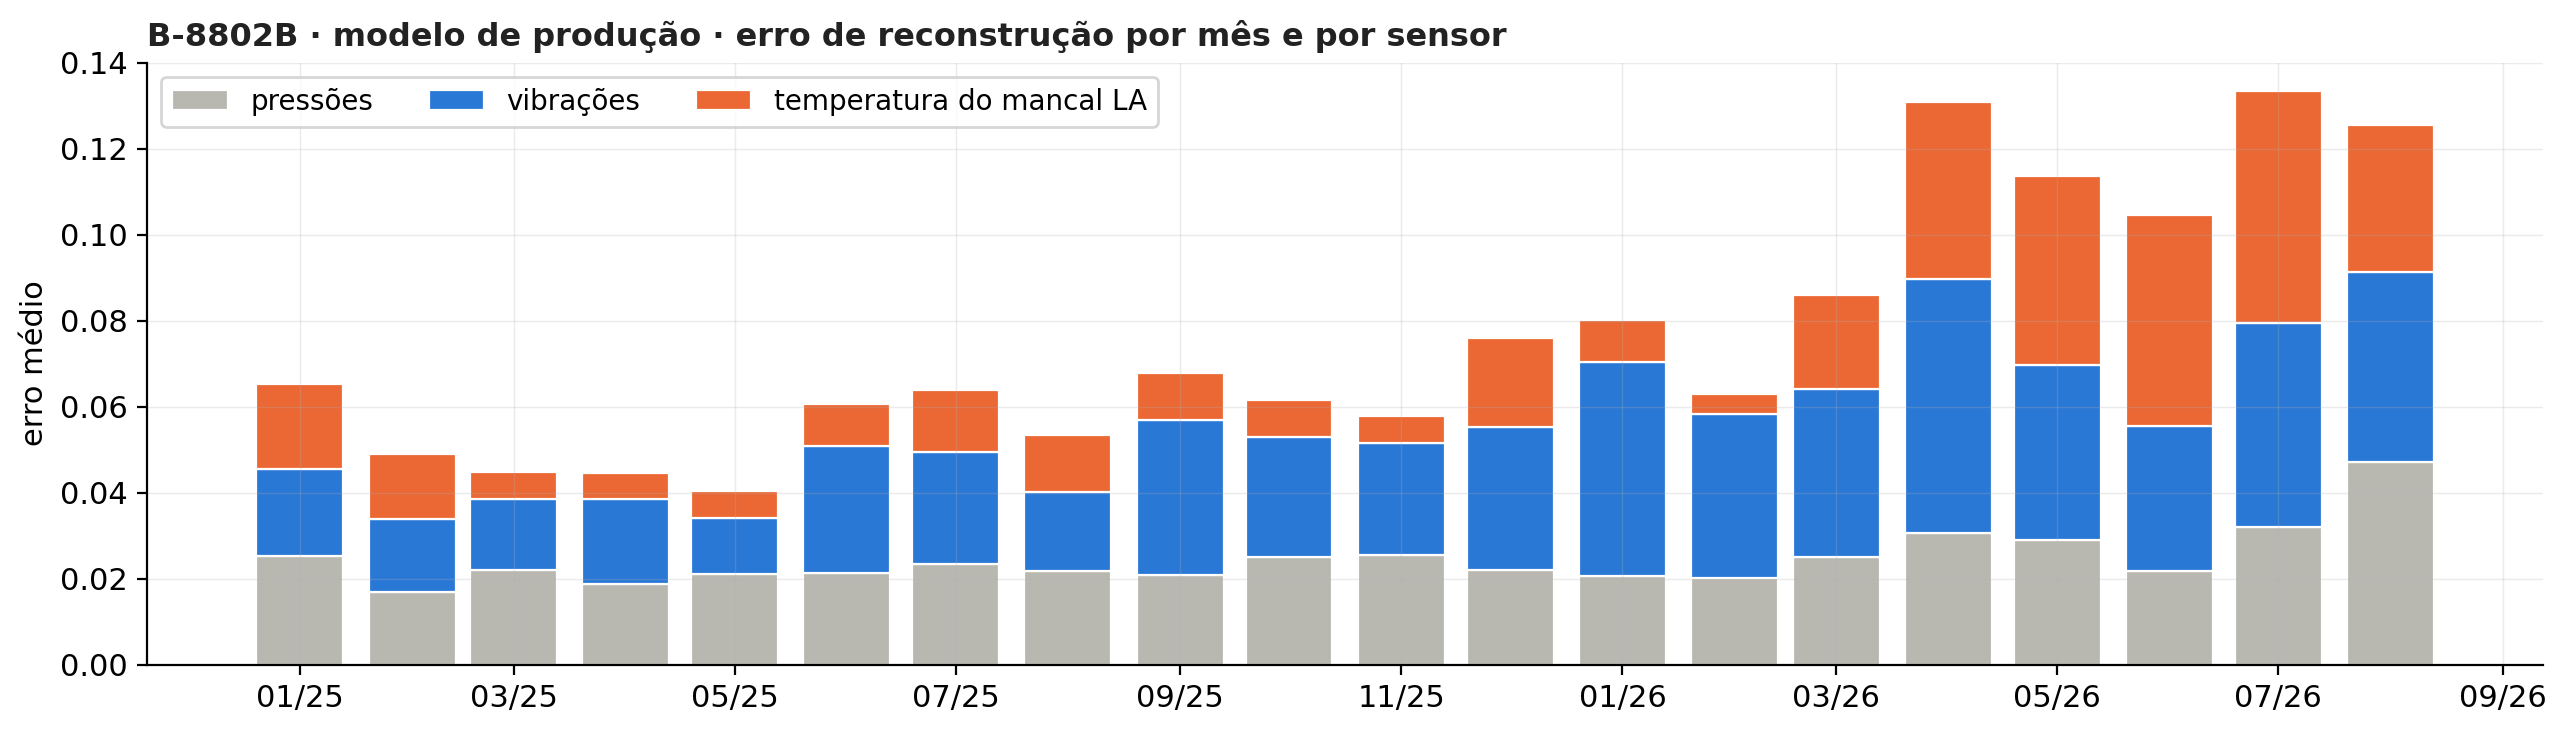

In [2]:
b = fx.BUNDLE; X = fx.si.preprocessar(b, ctx.raw); m = fx.si.carregar_modelo(b)
with torch.no_grad():
    x = torch.tensor(X.values, dtype=torch.float32); r = m(x)[0]
S = pd.DataFrame(((r - x) ** 2).numpy() / X.shape[1], index=X.index, columns=X.columns)
mes = S.resample("MS").mean()
grupos = {"pressões": (["Pressão Sucção", "Pressão Descarga"], "#b9b8b0"),
          "vibrações": (["Vibração Bomba LA", "Vibração Bomba LNA"], "#2a78d6"),
          "temperatura do mancal LA": (["Temperatura Bomba LA"], "#eb6834")}
fig, ax = plt.subplots(figsize=(13, 3.8)); base = np.zeros(len(mes))
for nome, (cols, cor) in grupos.items():
    v = mes[cols].sum(axis=1).values
    ax.bar(mes.index, v, bottom=base, width=24, color=cor, label=nome, edgecolor="white", lw=0.8); base += v
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y")); ax.set_ylabel("erro médio")
ax.legend(ncol=3, fontsize=10, loc="upper left")
estilo(ax, "B-8802B · modelo de produção · erro de reconstrução por mês e por sensor")
fig.tight_layout()

**Leitura:** em 2025 cada grupo pesa parecido. De abril a agosto de 2026 o erro dobra, e o aumento é quase todo da
**temperatura** (laranja): o mancal esfriou para ~45 °C, abaixo do que o modelo viu em 2025. Nada quebrou; o modelo só
estranha o frio.

## 2. Perto da falha real de 2022

Em cima, as vibrações e a temperatura. Embaixo, um modelo de cada receita:
- **linha clara** = score bruto (um ponto a cada 5 min — oscila bastante);
- **linha forte** = o mesmo score suavizado (mediana de 1 h), só para ler a tendência;
- **tracejada** = limiar. O alarme usa o score **bruto**: precisa ficar acima do limiar em 15 de 20 leituras (100 min)
  e durar 1 h — essa regra já faz o papel de "suavizar" na decisão;
- **faixa vermelha** = quando o modelo está em alerta.

,primeiro alerta,horas antes da falha
modelo,,
"produção (5 sensores, com temperatura)",04/07 08:10,50
sem temperatura (vibração + pressões),04/07 08:10,50
só vibração,04/07 08:05,50


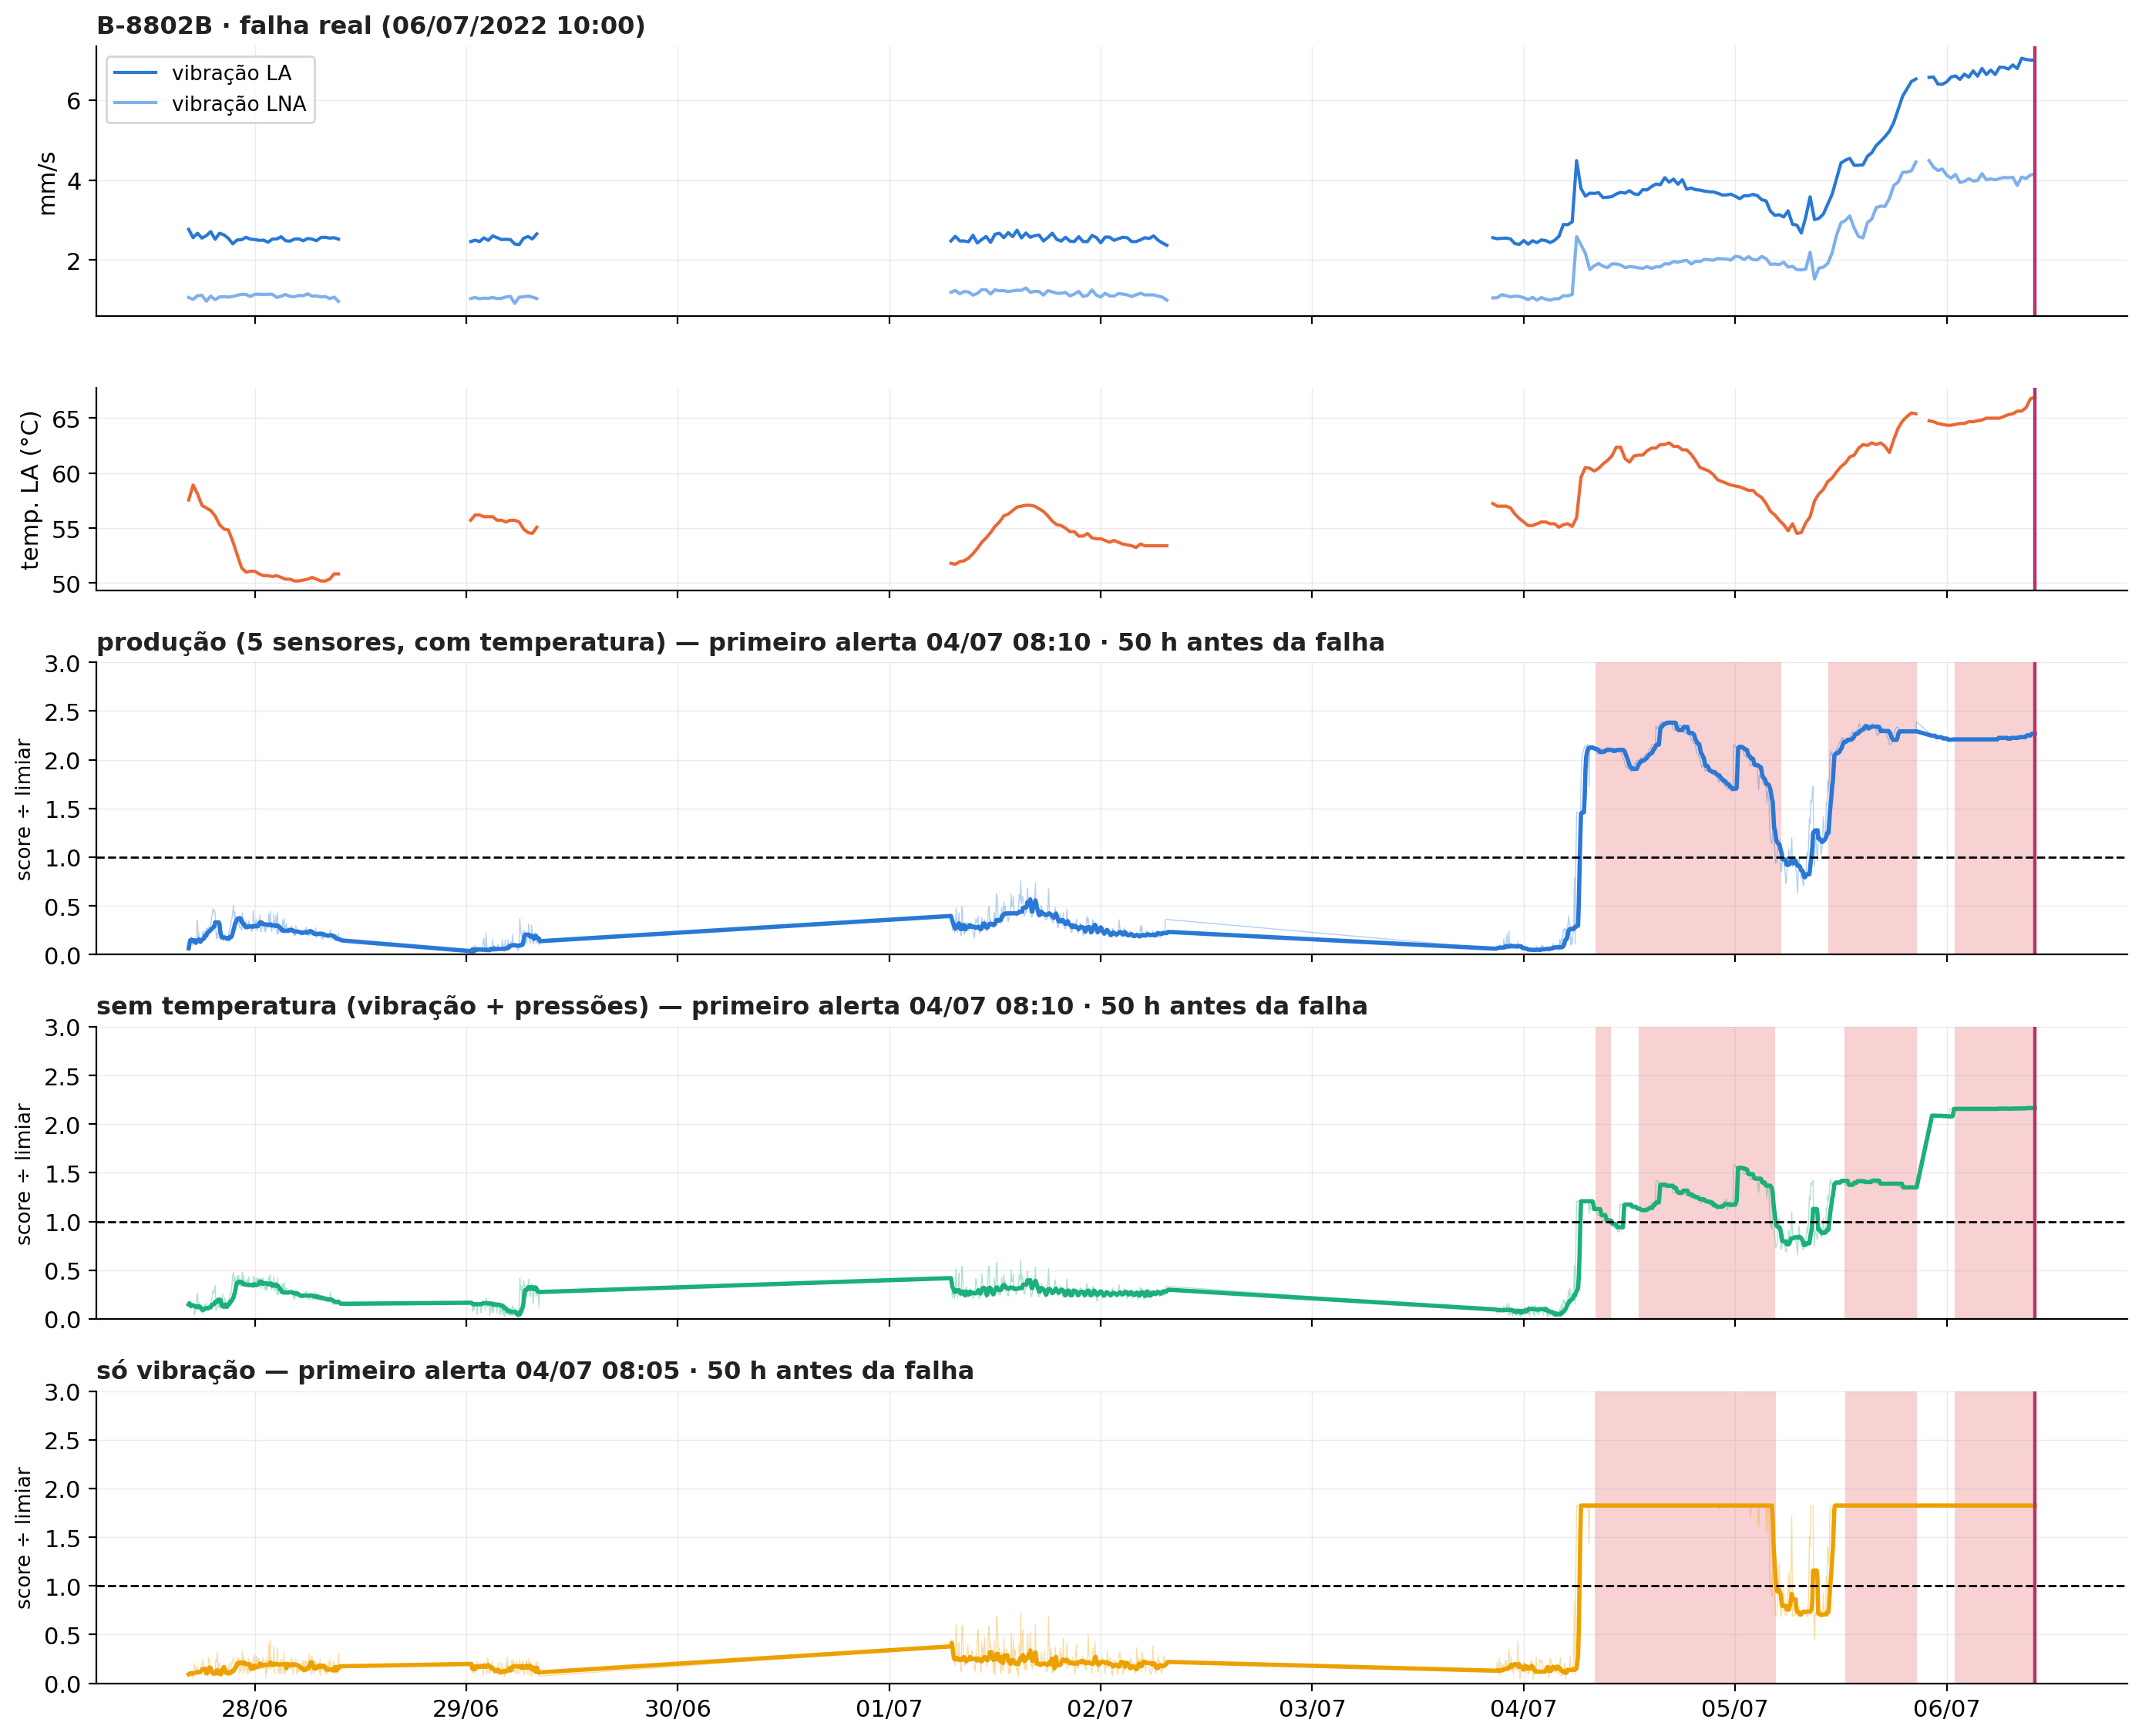

In [3]:
def painel(raw, ini, fim, marcos, titulo):
    pr = fx.temporal(raw.loc[ini:fim])
    fig, axes = plt.subplots(2 + len(MODELOS), 1, figsize=(14, 3 + 2.1 * (1 + len(MODELOS))), sharex=True,
                             gridspec_kw={"height_ratios": [1.2, 0.9] + [1.3] * len(MODELOS)})
    for c, cor, rot in [("Vibração Bomba LA", "#2a78d6", "vibração LA"), ("Vibração Bomba LNA", "#7fb0ec", "vibração LNA")]:
        d = pr[c].resample("30min").median(); axes[0].plot(d.index, d.values, color=cor, lw=1.5, label=rot)
    axes[0].set_ylabel("mm/s"); axes[0].legend(fontsize=9.5, loc="upper left"); estilo(axes[0], titulo)
    d = pr["Temperatura Bomba LA"].resample("30min").median()
    axes[1].plot(d.index, d.values, color="#eb6834", lw=1.5); axes[1].set_ylabel("temp. LA (°C)"); estilo(axes[1])
    linhas = []
    for ax, nome in zip(axes[2:], MODELOS):
        cor = MODELOS[nome][0]
        s, thr, al = score_e_alerta(nome, raw.loc[pd.Timestamp(ini) - pd.Timedelta(days=2):fim])
        s, al = s.loc[ini:fim] / thr, al.loc[ini:fim]
        ax.plot(s.index, s.values, color=cor, lw=0.5, alpha=0.35)
        sm = s.groupby(fx.segmentos(s.index)).transform(lambda v: v.rolling(12, min_periods=1).median())
        ax.plot(sm.index, sm.values, color=cor, lw=2)
        ax.axhline(1, color="black", ls="--", lw=1)
        on = al[al]
        for _, g in on.groupby(on.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()):
            ax.axvspan(g.index[0], g.index[-1], color="#e5484d", alpha=0.25, lw=0)
        prim = al.loc[marcos["inicio"]:marcos["fim"]]
        t1 = prim[prim].index.min() if prim.any() else None
        txt = (f"primeiro alerta {t1:%d/%m %H:%M} · {(marcos['fim'] - t1).total_seconds() / 3600:.0f} h antes {marcos['rot']}"
               if t1 is not None else "não alerta")
        ax.set_ylim(0, max(3, float(sm.quantile(0.995)) * 1.15)); ax.set_ylabel("score ÷ limiar", fontsize=9.5)
        estilo(ax, f"{nome} — {txt}")
        linhas.append({"modelo": nome, "primeiro alerta": None if t1 is None else f"{t1:%d/%m %H:%M}",
                       f"horas antes {marcos['rot']}": None if t1 is None else round((marcos["fim"] - t1).total_seconds() / 3600)})
    for ax in axes:
        ax.axvline(marcos["fim"], color="#b8336a", lw=1.6)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.tight_layout()
    return pd.DataFrame(linhas).set_index("modelo")

painel(ctx.raw22, "2022-06-27", "2022-07-06 10:00",
       {"inicio": fx.R0, "fim": fx.FAIL, "rot": "da falha"}, "B-8802B · falha real (06/07/2022 10:00)")

**Leitura:** até 04/07 as vibrações estão normais (~2,5 e ~1 mm/s) e nenhum score chega perto do limiar. Em 04/07
a vibração salta (LA 2,5 → 3,8; LNA 1 → 2 mm/s) e os **três** modelos passam do limiar ao mesmo tempo, ~50 h antes da
falha. Como a falha está na vibração, um modelo só de vibração **não** avisa antes: os outros também têm a vibração e
reagem no mesmo instante. A temperatura sobe junto, mas não antecipa nada.

O score do "só vibração" fica num patamar reto em ~1,8: as entradas são cortadas no máximo visto em 2025 (o mesmo
corte do modelo de produção), então acima disso o score não cresce mais — para o alarme isso não muda nada, ele já
passou do limiar.

## 3. Em 2026, sem falha conhecida

Mesmo formato, de janeiro a agosto de 2026. O ideal aqui é **não** alertar (exceto em 17/01, um episódio de vibração
que tratamos como real).

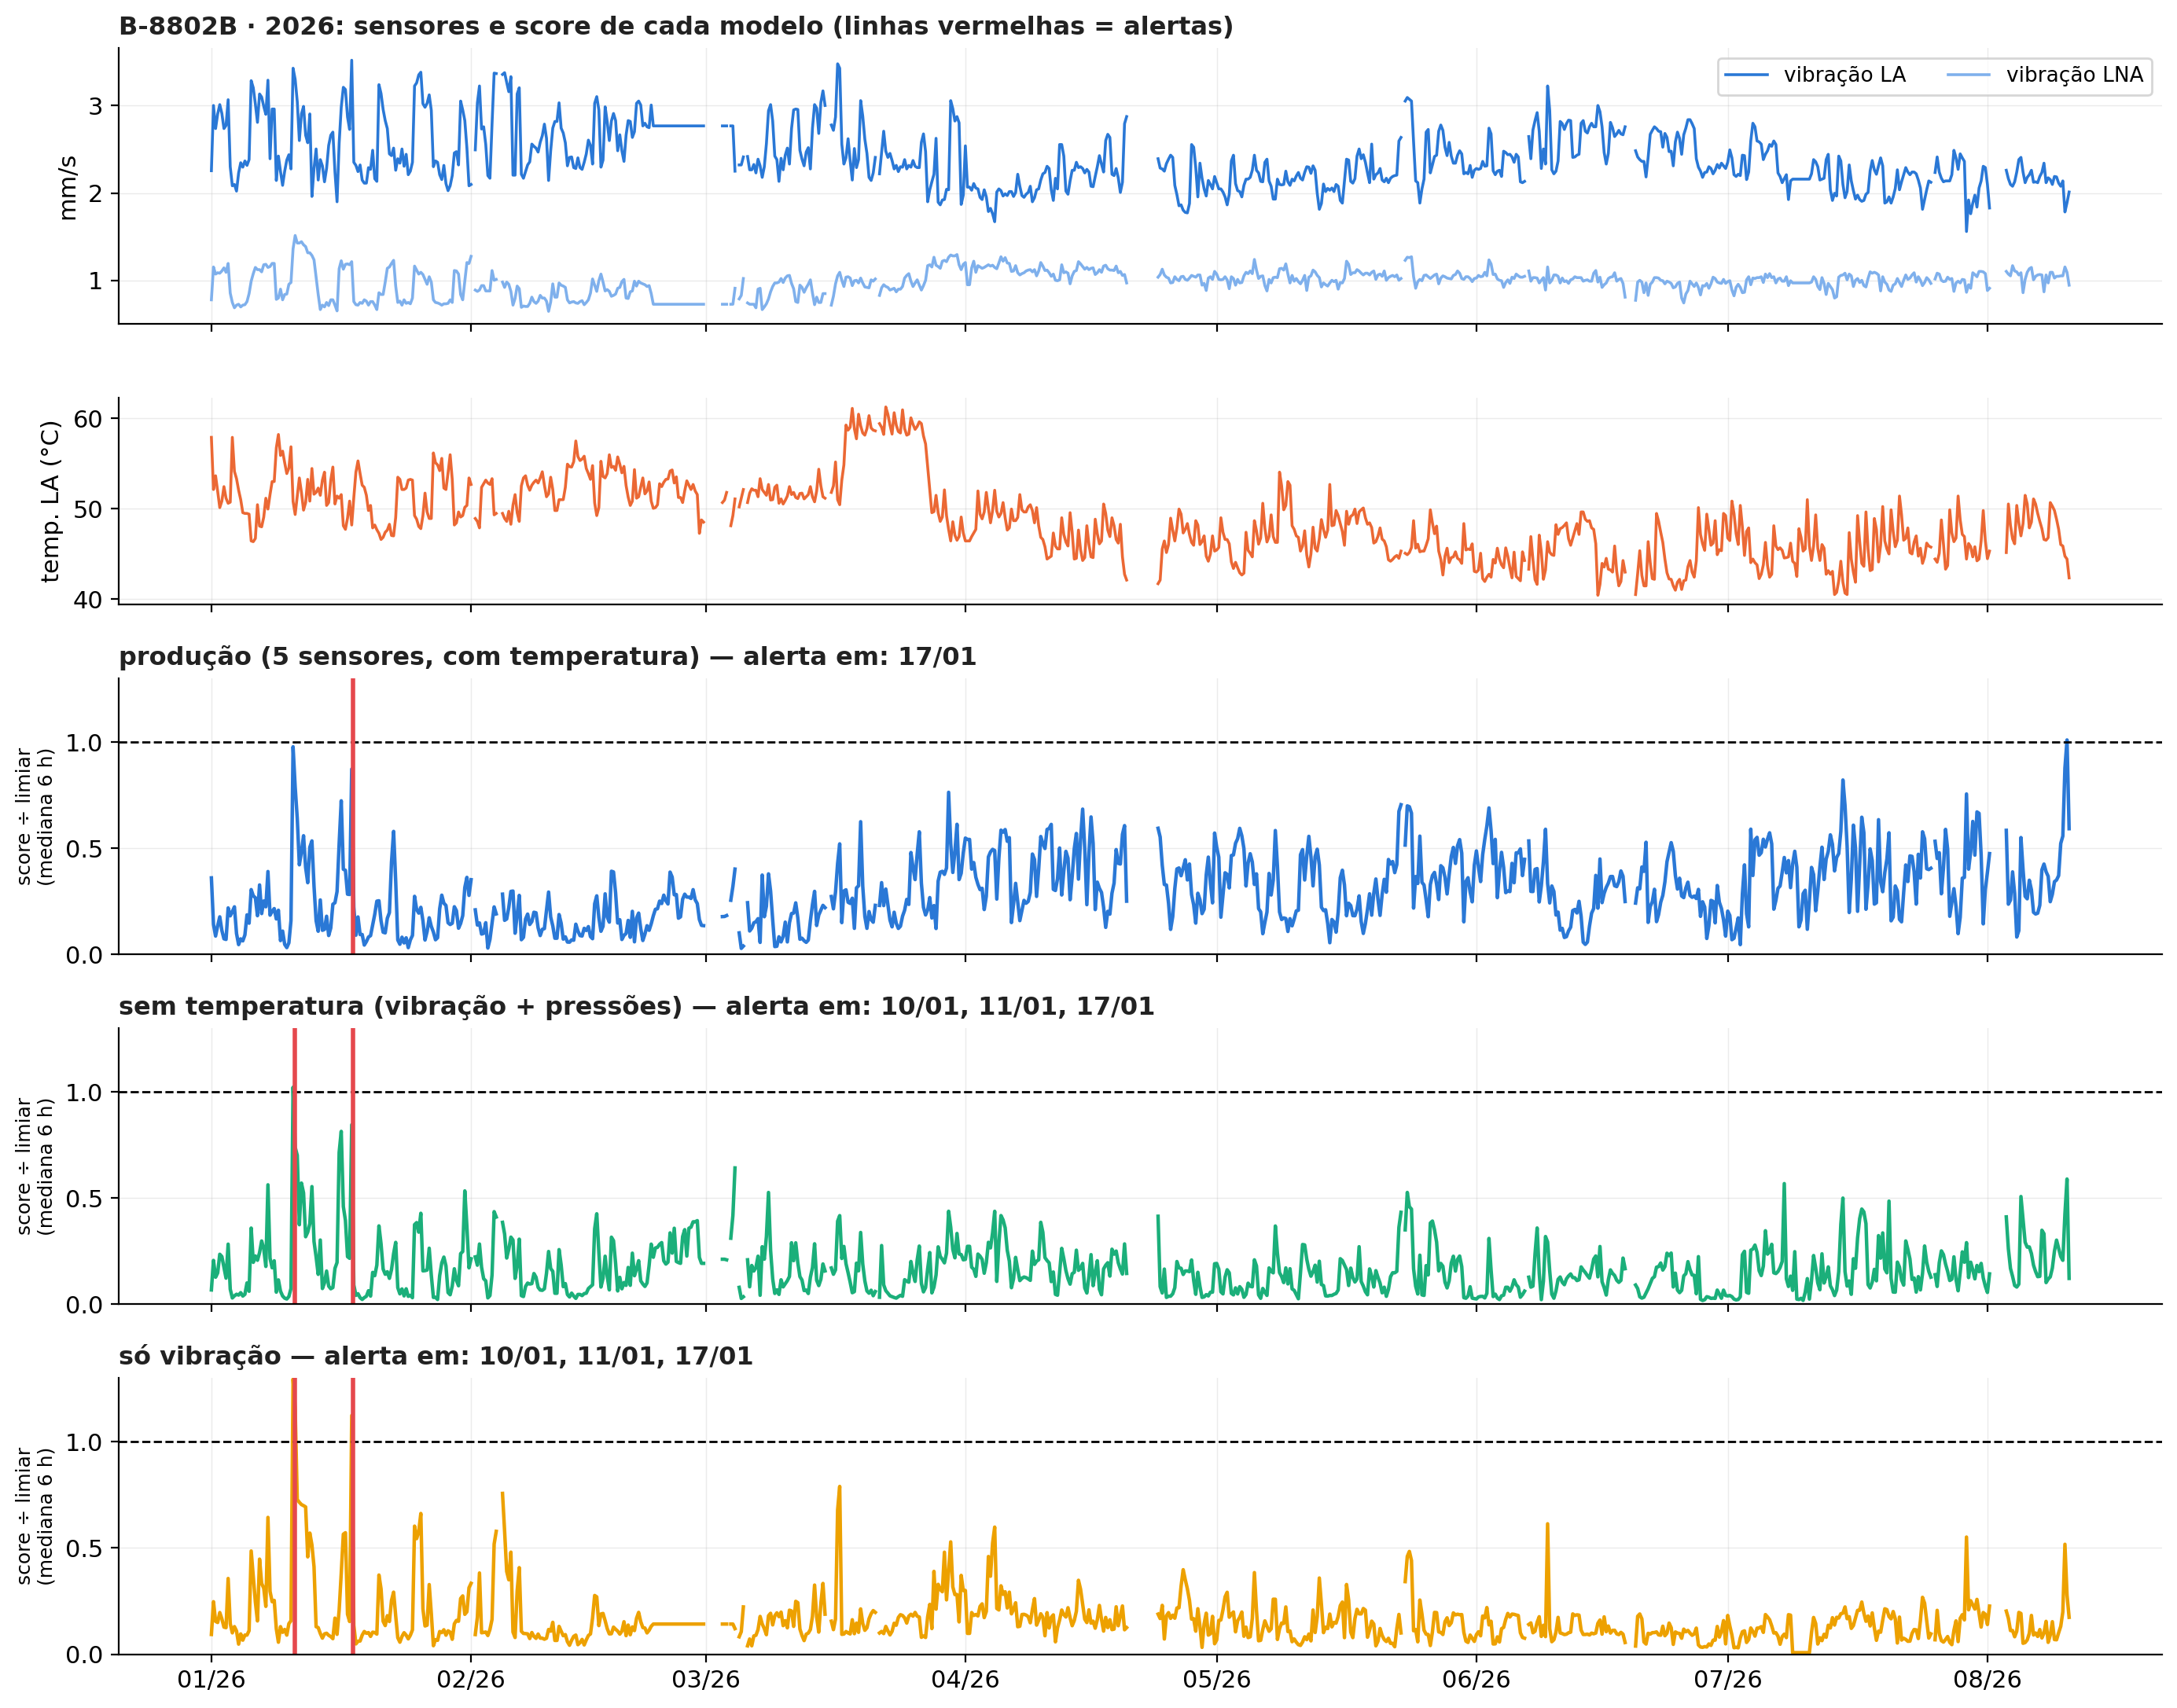

In [4]:
def painel_2026(ini, fim, titulo):
    raw = ctx.raw.loc[ini:fim]; pr = fx.temporal(raw)
    fig, axes = plt.subplots(2 + len(MODELOS), 1, figsize=(14, 3 + 2.0 * (1 + len(MODELOS))), sharex=True,
                             gridspec_kw={"height_ratios": [1.2, 0.9] + [1.2] * len(MODELOS)})
    for c, cor, rot in [("Vibração Bomba LA", "#2a78d6", "vibração LA"), ("Vibração Bomba LNA", "#7fb0ec", "vibração LNA")]:
        d = pr[c].resample("6h").median(); axes[0].plot(d.index, d.values, color=cor, lw=1.3, label=rot)
    axes[0].set_ylabel("mm/s"); axes[0].legend(fontsize=9.5, loc="upper right", ncol=2); estilo(axes[0], titulo)
    d = pr["Temperatura Bomba LA"].resample("6h").median()
    axes[1].plot(d.index, d.values, color="#eb6834", lw=1.3); axes[1].set_ylabel("temp. LA (°C)"); estilo(axes[1])
    for ax, nome in zip(axes[2:], MODELOS):
        cor = MODELOS[nome][0]
        s, thr, al = score_e_alerta(nome, raw)
        s = s / thr
        d = s.resample("6h").median()
        ax.plot(d.index, d.values, color=cor, lw=1.6)
        ax.axhline(1, color="black", ls="--", lw=1)
        on = al[al]
        for _, g in on.groupby(on.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()):
            ax.axvline(g.index[0], color="#e5484d", lw=2)
        dias = sorted({t.strftime("%d/%m") for t in on.index})
        ax.set_ylim(0, 1.3); ax.set_ylabel("score ÷ limiar\n(mediana 6 h)", fontsize=9)
        estilo(ax, f"{nome} — alerta em: {', '.join(dias) if dias else 'nenhum dia'}")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    fig.tight_layout()

painel_2026("2026-01-01", "2026-08-10", "B-8802B · 2026: sensores e score de cada modelo (linhas vermelhas = alertas)")

**Leitura:**
- **Produção**: o score sobe aos poucos de abril em diante, acompanhando o esfriamento (temperatura caindo). Ainda não
  alerta, mas está mais perto do limiar do que precisaria — e o monitor de drift lê isso como "o modelo envelheceu".
- **Sem temperatura**: o score fica estável o ano todo; alerta só nos dois episódios de vibração de janeiro (10–12/01 e 17/01).
- **Só vibração**: também estável, mas alerta mais vezes em janeiro. Sem as pressões, o modelo não sabe em que regime
  a bomba está, e vibração que é normal num regime parece estranha.

## 4. Veredito

Os números abaixo vêm de 6 modelos por receita (sementes diferentes), com a mesma regra de alarme de produção.

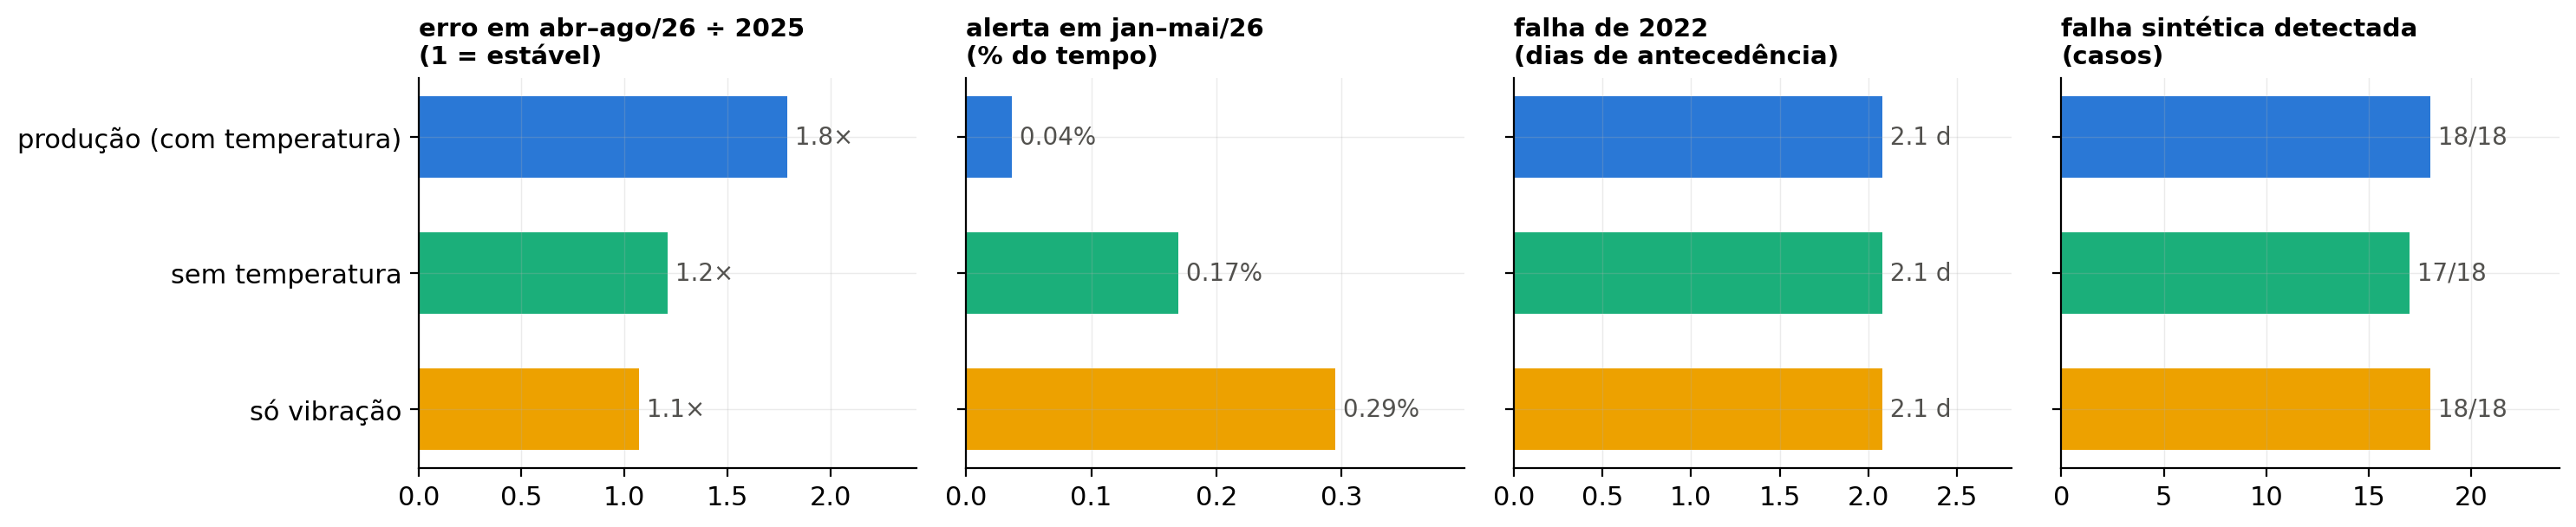

In [5]:
av = pd.read_csv(R / "avaliacao.csv"); ep = pd.read_csv(R / "episodios.csv")
g = av[av.modo == "bruto"].merge(ep[ep.modo == "bruto"][["variante", "cand", "ancora_17jan"]], on=["variante", "cand"])
s100 = [c for c in g if c.startswith("sint100")]
g["sint"] = (g[s100] > 0).sum(axis=1); g["sint_n"] = g[s100].notna().sum(axis=1)
NOMES = {"base": "produção (com temperatura)", "vib_press": "sem temperatura", "vib": "só vibração"}
t = g[g.variante.isin(NOMES)].groupby("variante").agg(
    erro=("erro_2026T2T3/2025", "median"), janmai=("alerta_jan-mai26_%", "median"), ancora=("ancora_17jan", "sum"),
    f22=("falha2022_dias", "median"), sint=("sint", "sum"), sint_n=("sint_n", "sum")).reindex(list(NOMES))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
cores = ["#2a78d6", "#1baf7a", "#eda100"]
for ax, (col, tit, fmt) in zip(axes, [("erro", "erro em abr–ago/26 ÷ 2025\n(1 = estável)", "{:.1f}×"),
                                     ("janmai", "alerta em jan–mai/26\n(% do tempo)", "{:.2f}%"),
                                     ("f22", "falha de 2022\n(dias de antecedência)", "{:.1f} d"),
                                     ("sint", "falha sintética detectada\n(casos)", None)]):
    ax.barh(range(3), t[col], color=cores, height=0.6)
    for i, (k, r) in enumerate(t.iterrows()):
        lab = f"{int(r.sint)}/{int(r.sint_n)}" if col == "sint" else fmt.format(r[col])
        ax.text(r[col], i, " " + lab, va="center", fontsize=10, color=TEXTO)
    ax.set_title(tit, loc="left", fontsize=10.5, fontweight="bold"); estilo(ax)
    ax.set_xlim(0, t[col].max() * 1.35)
axes[0].set_yticks(range(3), [NOMES[k] for k in t.index]); axes[0].invert_yaxis()
fig.tight_layout()

| | produção (com temperatura) | **sem temperatura** | só vibração |
|---|---|---|---|
| erro em 2026 | sobe 1,8× (esfriamento) | **estável (1,2×)** | estável (1,1×) |
| falha de 2022 | ~2 dias | ~2 dias | ~2 dias |
| falha sintética | detecta | detecta | detecta |
| alertas sem falha (jan/26) | poucos, mas perde 17/01 em parte dos modelos | os dois episódios de janeiro | mais alertas |

**Conclusão:** a falha está na vibração, então todos detectam igual. Tirar a temperatura deixa o modelo estável em
2026 sem perder detecção; tirar também as pressões (só vibração) aumenta os alertas. A receita **sem temperatura** é a
candidata — falta confirmar com a operação se o episódio de **10–12/01/2026** foi real (se foi, ela é claramente
melhor). A temperatura passa a ser vigiada por fora (monitor M8).

**Descartado (detalhes no outro notebook):** só temperaturas, espectro das vibrações, variação da temperatura, PCA,
LSTM e redes com janela de 2 h, autoencoder denso.